# SAIA 1173 — Multiple Linear Regression Analysis
**Dataset:** Medical Insurance Cost  
**Source:** https://www.kaggle.com/datasets/mirichoi0218/insurance  
**Software:** Python (pandas, statsmodels, matplotlib, seaborn)

> Place `insurance.csv` in the same folder as this notebook before running.

## 1. Introduction, Problem Background & Objectives

### 1.1 Introduction

Healthcare expenditure is a growing concern for individuals, insurance providers, and policymakers worldwide. Understanding the factors that drive medical costs is essential for enabling more accurate premium pricing, better resource allocation, and informed financial planning. In Malaysia and globally, rising healthcare costs have prompted the need for data-driven approaches to identify key cost determinants and predict future expenses.

This project applies **Multiple Linear Regression (MLR)** — a widely used statistical modelling technique — to analyse and predict individual medical insurance charges based on a set of demographic and lifestyle-related variables. MLR is particularly suitable for this problem because it models the linear relationship between a continuous dependent variable (medical charges) and multiple independent predictors simultaneously, while providing interpretable coefficients and statistical significance measures.

### 1.2 Background of the Problem

Medical insurance costs vary significantly across individuals depending on a range of personal attributes. Age, body mass index (BMI), smoking status, number of dependants, and sex are commonly cited factors that influence health risk profiles and, consequently, the cost of insurance coverage. Insurance companies rely heavily on actuarial models to set premiums, yet transparent, regression-based approaches remain valuable for academic analysis and practical estimation.

The Medical Insurance Cost dataset, sourced from Kaggle (originally introduced by Brett Lantz in *Machine Learning with R*), provides a real-world record of 1,338 individuals with information on the above attributes alongside their billed insurance charges. The dataset is well-structured, publicly available, and widely used in applied statistics and machine learning education, making it appropriate for this regression study.

### 1.3 Problem Statement

Despite the availability of individual-level demographic and lifestyle data, it is not straightforward to quantify how much each factor contributes to a person's medical insurance cost, or to what degree a linear model can reliably predict charges. This project addresses the following question:

> *To what extent can age, BMI, number of children, smoking status, and sex predict individual medical insurance charges using Multiple Linear Regression?*

### 1.4 Project Objectives

The objectives of this project are as follows:

1. To perform descriptive statistical analysis and data visualisation on the Medical Insurance Cost dataset.
2. To examine the correlation between each independent variable and medical insurance charges.
3. To develop a Multiple Linear Regression model that predicts medical insurance charges based on selected predictors.
4. To evaluate the model's performance using R², Adjusted R², the ANOVA F-test, and residual diagnostic plots.
5. To identify the most significant predictors of medical insurance charges and discuss their practical implications.


## 0. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Plot style
plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
PALETTE = ['#2D6A9F', '#E07B39', '#2DA071', '#C0392B', '#8E44AD']
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 1. Load & Inspect Dataset

In [2]:
df = pd.read_csv('insurance.csv')

print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'\nColumn names: {list(df.columns)}')
print(f'\nData types:\n{df.dtypes}')
print(f'\nMissing values:\n{df.isnull().sum()}')
df.head(10)

Shape: 1338 rows × 7 columns

Column names: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


### Variable Descriptions
| Variable | Role | Type | Description |
|---|---|---|---|
| `charges` | Dependent (Y) | Numerical | Individual medical costs billed by insurance (USD) |
| `age` | Independent (X₁) | Numerical | Age of the primary beneficiary |
| `bmi` | Independent (X₂) | Numerical | Body mass index (kg/m²) |
| `children` | Independent (X₃) | Numerical | Number of dependants covered |
| `smoker` | Independent (X₄) | Categorical → encoded | Smoking status (yes=1, no=0) |
| `sex` | Independent (X₅) | Categorical → encoded | Sex (male=1, female=0) |
| `region` | — | Categorical | Residential area in the US (not used as primary predictor) |

## 2. Data Preprocessing

In [ ]:
# Encode categorical variables
df['sex_enc']    = df['sex'].map({'male': 1, 'female': 0})
df['smoker_enc'] = df['smoker'].map({'yes': 1, 'no': 0})

# Define predictors and target
PREDICTORS = ['age', 'bmi', 'children', 'smoker_enc', 'sex_enc']
TARGET = 'charges'

print('Encoding complete.')
print(f'Smoker distribution:\n{df["smoker"].value_counts()}')
print(f'\nSex distribution:\n{df["sex"].value_counts()}')

Encoding complete.
Smoker distribution:
smoker
no     1064
yes     274
Name: count, dtype: int64

Sex distribution:
sex
male      676
female    662
Name: count, dtype: int64


## 3. Descriptive Statistics

In [4]:
desc = df[PREDICTORS + [TARGET]].describe().T
desc['cv (%)'] = (desc['std'] / desc['mean'] * 100).round(2)

# Rename for clarity
desc.index = ['Age', 'BMI', 'Children', 'Smoker (encoded)', 'Sex (encoded)', 'Charges (USD)']
desc[['count','mean','std','min','25%','50%','75%','max','cv (%)']].round(3)

,count,mean,std,min,25%,50%,75%,max,cv (%)
Age,1338.0,39.207,14.050,18.000,27.000,39.000,51.000,64.000,35.84
BMI,1338.0,30.663,6.098,15.960,26.296,30.400,34.694,53.130,19.89
Children,1338.0,1.095,1.205,0.000,0.000,1.000,2.000,5.000,110.10
Smoker (encoded),1338.0,0.205,0.404,0.000,0.000,0.000,0.000,1.000,197.13
Sex (encoded),1338.0,0.505,0.500,0.000,0.000,1.000,1.000,1.000,99.00
Charges (USD),1338.0,13270.422,12110.011,1121.874,4740.287,9382.033,16639.913,63770.428,91.26


In [5]:
# Skewness and Kurtosis
print('Skewness and Kurtosis:')
sk_df = df[PREDICTORS + [TARGET]].agg(['skew','kurt']).T
sk_df.index = ['Age', 'BMI', 'Children', 'Smoker (enc)', 'Sex (enc)', 'Charges']
sk_df.round(4)

Skewness and Kurtosis:


,skew,kurt
Age,0.0557,-1.2451
BMI,0.2840,-0.0507
Children,0.9384,0.2025
Smoker (enc),1.4648,0.1458
Sex (enc),-0.0210,-2.0026
Charges,1.5159,1.6063


## 4. Data Visualization

### 4.1 Distribution of Medical Charges

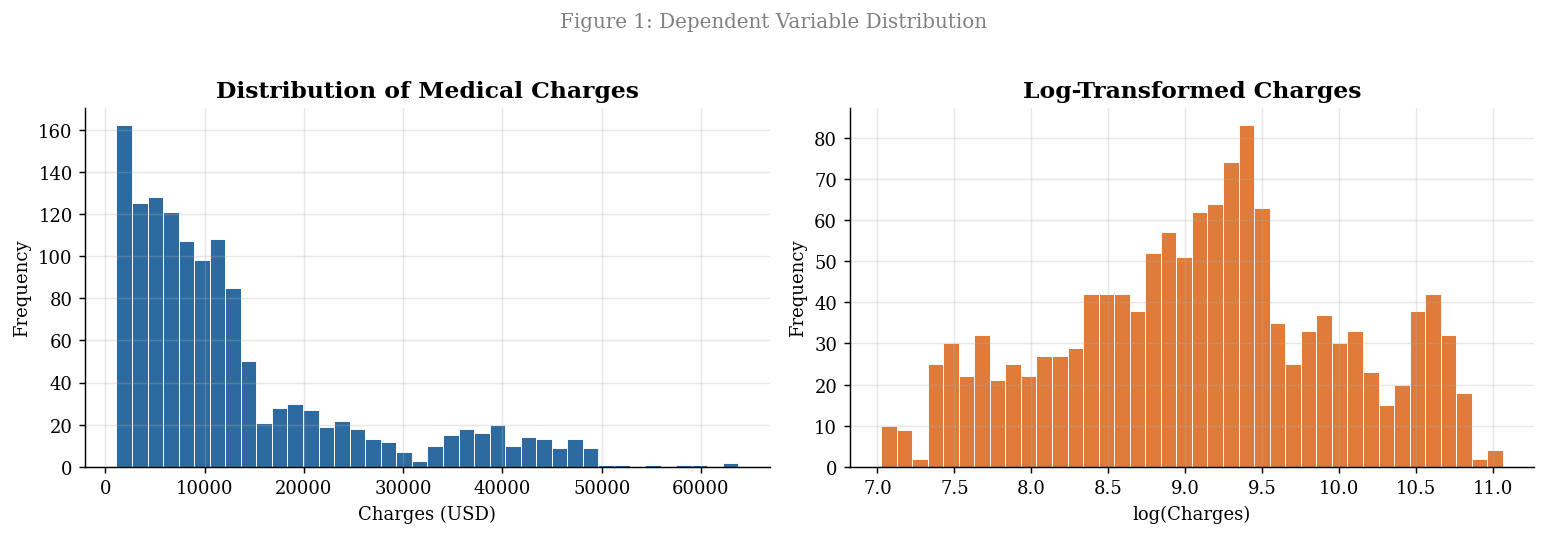

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df[TARGET], bins=40, color=PALETTE[0], edgecolor='white', linewidth=0.5)
axes[0].set_title('Distribution of Medical Charges', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Charges (USD)')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log(df[TARGET]), bins=40, color=PALETTE[1], edgecolor='white', linewidth=0.5)
axes[1].set_title('Log-Transformed Charges', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Charges)')
axes[1].set_ylabel('Frequency')

plt.suptitle('Figure 1: Dependent Variable Distribution', y=1.02, fontsize=11, color='gray')
plt.tight_layout()
plt.savefig('fig1_charges_distribution.png', bbox_inches='tight')
plt.show()

### 4.2 Scatter Plots: Predictors vs Charges

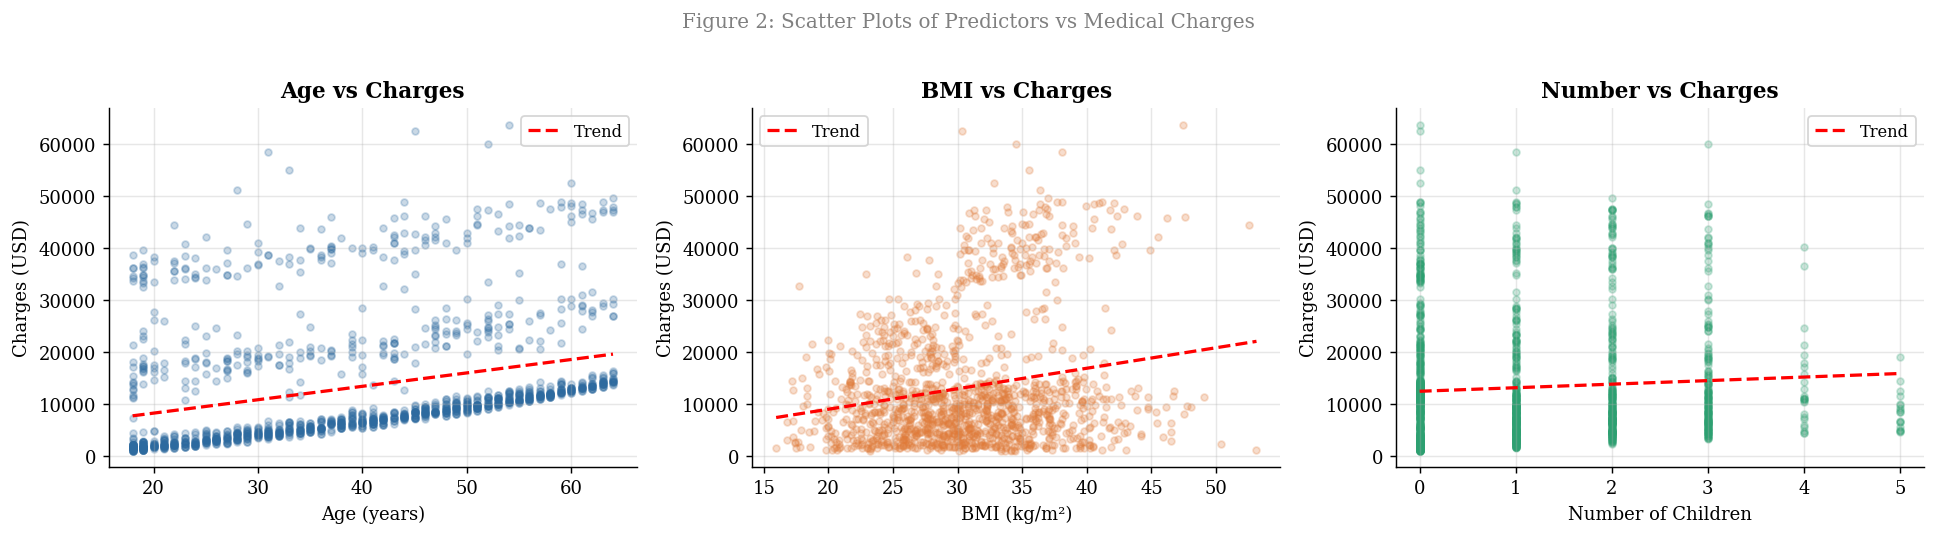

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
scatter_vars = ['age', 'bmi', 'children']
labels = ['Age (years)', 'BMI (kg/m²)', 'Number of Children']

for i, (var, label) in enumerate(zip(scatter_vars, labels)):
    axes[i].scatter(df[var], df[TARGET], alpha=0.25, s=14, color=PALETTE[i])
    m, b = np.polyfit(df[var], df[TARGET], 1)
    x_line = np.linspace(df[var].min(), df[var].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.8, linestyle='--', label='Trend')
    axes[i].set_xlabel(label)
    axes[i].set_ylabel('Charges (USD)')
    axes[i].set_title(f'{label.split(" ")[0]} vs Charges', fontweight='bold')
    axes[i].legend(fontsize=9)

plt.suptitle('Figure 2: Scatter Plots of Predictors vs Medical Charges', y=1.02, fontsize=11, color='gray')
plt.tight_layout()
plt.savefig('fig2_scatter_plots.png', bbox_inches='tight')
plt.show()

### 4.3 Boxplots by Categorical Groups

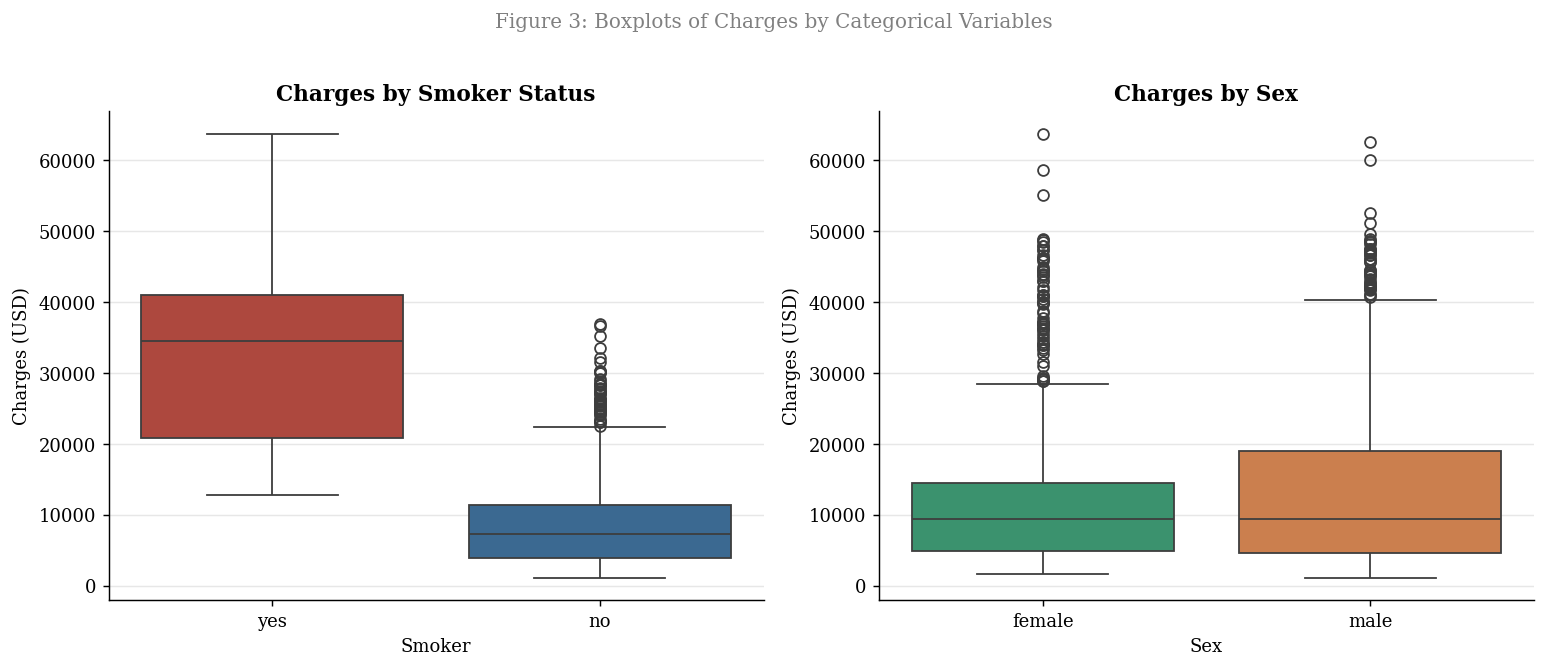

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='smoker', y=TARGET, ax=axes[0],
            palette={'yes': PALETTE[3], 'no': PALETTE[0]})
axes[0].set_title('Charges by Smoker Status', fontweight='bold')
axes[0].set_xlabel('Smoker')
axes[0].set_ylabel('Charges (USD)')

sns.boxplot(data=df, x='sex', y=TARGET, ax=axes[1],
            palette={'male': PALETTE[1], 'female': PALETTE[2]})
axes[1].set_title('Charges by Sex', fontweight='bold')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Charges (USD)')

plt.suptitle('Figure 3: Boxplots of Charges by Categorical Variables', y=1.02, fontsize=11, color='gray')
plt.tight_layout()
plt.savefig('fig3_boxplots.png', bbox_inches='tight')
plt.show()

### 4.4 Histogram of All Numerical Predictors

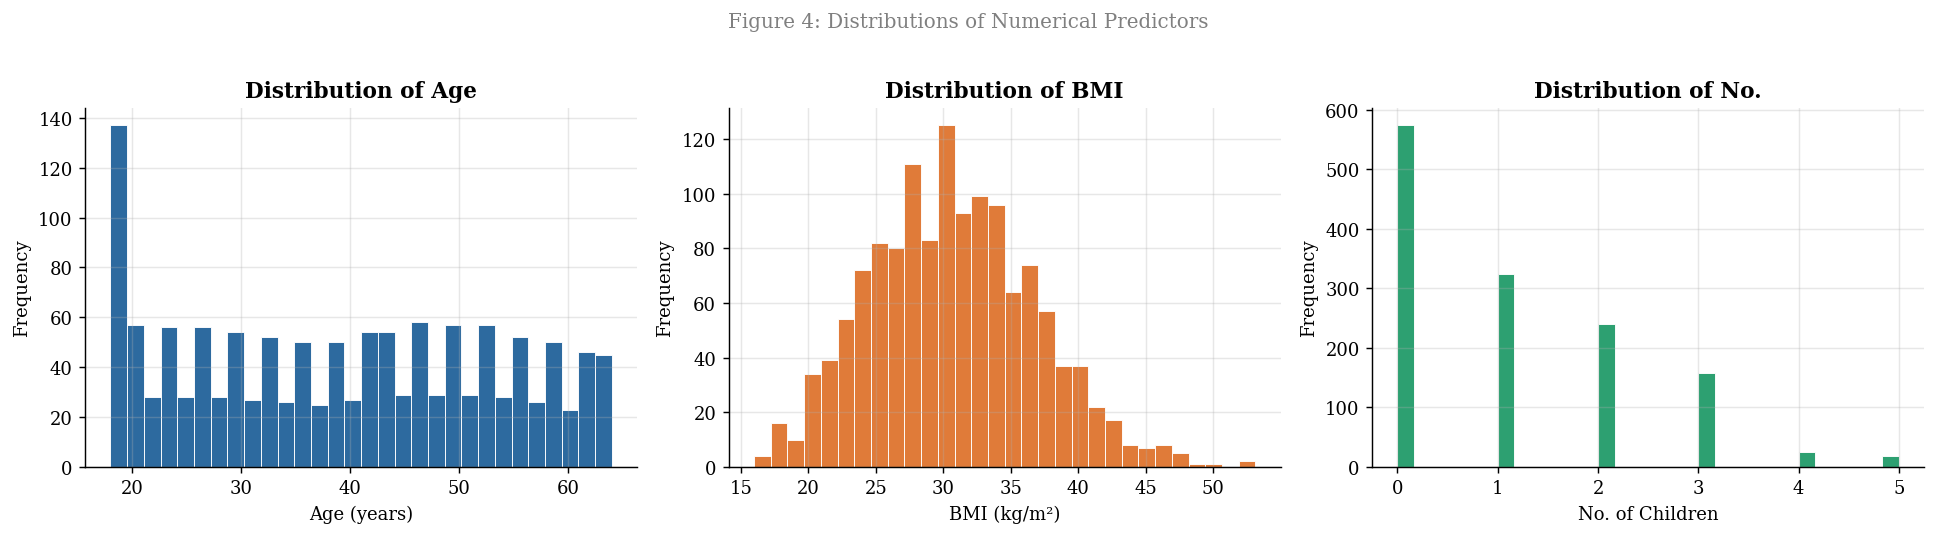

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
hist_vars = [('age', 'Age (years)'), ('bmi', 'BMI (kg/m²)'), ('children', 'No. of Children')]

for i, (var, label) in enumerate(hist_vars):
    axes[i].hist(df[var], bins=30, color=PALETTE[i], edgecolor='white', linewidth=0.5)
    axes[i].set_xlabel(label)
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Distribution of {label.split(" ")[0]}', fontweight='bold')

plt.suptitle('Figure 4: Distributions of Numerical Predictors', y=1.02, fontsize=11, color='gray')
plt.tight_layout()
plt.savefig('fig4_predictor_distributions.png', bbox_inches='tight')
plt.show()

## 5. Correlation Analysis

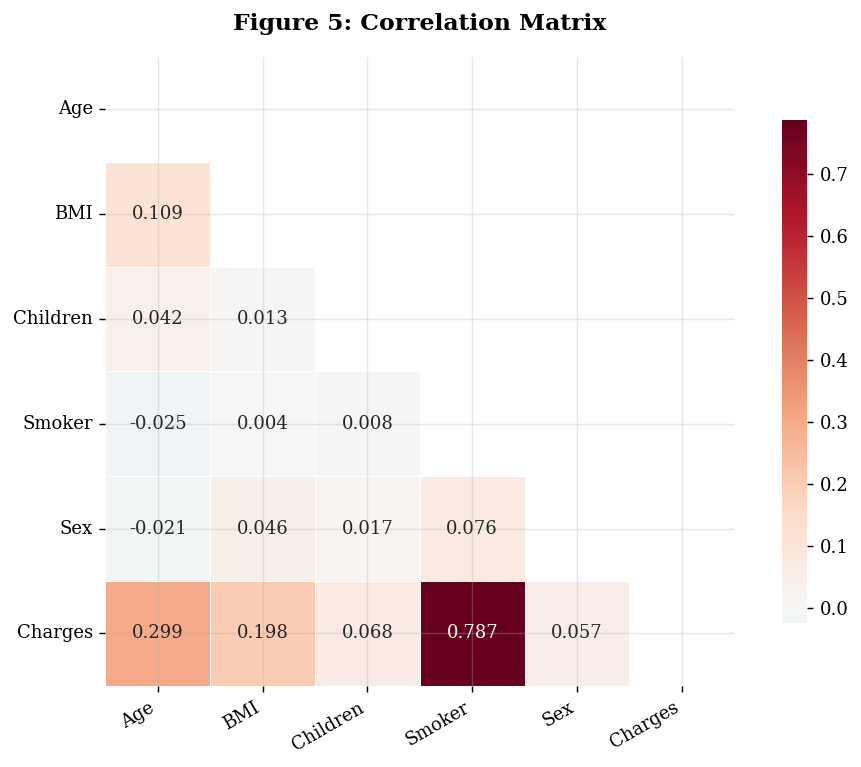

In [10]:
corr_matrix = df[PREDICTORS + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, square=True, mask=mask, ax=ax,
            linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 10})
ax.set_title('Figure 5: Correlation Matrix', fontsize=13, fontweight='bold', pad=15)
ax.set_xticklabels(['Age','BMI','Children','Smoker','Sex','Charges'], rotation=30, ha='right')
ax.set_yticklabels(['Age','BMI','Children','Smoker','Sex','Charges'], rotation=0)
plt.tight_layout()
plt.savefig('fig5_correlation_heatmap.png', bbox_inches='tight')
plt.show()

In [ ]:
print('Pearson Correlation with Charges:')
print('-' * 50)
results = []
for col in PREDICTORS:
    r, p = stats.pearsonr(df[col], df[TARGET])
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    strength = 'Strong' if abs(r) > 0.5 else ('Moderate' if abs(r) > 0.3 else 'Weak')
    direction = 'Positive' if r > 0 else 'Negative'
    results.append({'Predictor': col, 'r': round(r,4), 'p-value': round(p,4),
                    'Sig.': sig, 'Strength': strength, 'Direction': direction})

corr_df = pd.DataFrame(results).set_index('Predictor')
print(corr_df.to_string())

Pearson Correlation with Charges:
--------------------------------------------------
                 r  p-value Sig. Strength Direction
Predictor                                          
age         0.2990   0.0000  ***     Weak  Positive
bmi         0.1983   0.0000  ***     Weak  Positive
children    0.0680   0.0129    *     Weak  Positive
smoker_enc  0.7873   0.0000  ***   Strong  Positive
sex_enc     0.0573   0.0361    *     Weak  Positive


## 6. Multiple Linear Regression

In [12]:
X = df[PREDICTORS]
y = df[TARGET]
X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     798.0
Date:                Tue, 16 Jun 2026   Prob (F-statistic):               0.00
Time:                        09:48:53   Log-Likelihood:                -13551.
No. Observations:                1338   AIC:                         2.711e+04
Df Residuals:                    1332   BIC:                         2.715e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.205e+04    951.260    -12.670      0.0

### 6.1 Regression Equation

In [13]:
intercept = model.params['const']
coefs = {col: model.params[col] for col in PREDICTORS}
labels = {'age':'age', 'bmi':'bmi', 'children':'children',
          'smoker_enc':'smoker', 'sex_enc':'sex'}

eq = f'charges = {intercept:.4f}'
for col in PREDICTORS:
    sign = '+' if coefs[col] >= 0 else '-'
    eq += f' {sign} {abs(coefs[col]):.4f}×{labels[col]}'

print('REGRESSION EQUATION')
print('─' * 60)
print(f'  ŷ  =  {eq[len("charges = "):]}')
print()
print('COEFFICIENT INTERPRETATION')
print('─' * 60)
for col in PREDICTORS:
    p = model.pvalues[col]
    sig = '(significant)' if p < 0.05 else '(NOT significant)'
    print(f'  {labels[col]:<10}: β = {coefs[col]:+,.4f}  |  p = {p:.4f}  {sig}')

REGRESSION EQUATION
────────────────────────────────────────────────────────────
  ŷ  =  -12052.4620 + 257.7350×age + 322.3642×bmi + 474.4111×children + 23823.3925×smoker - 128.6399×sex

COEFFICIENT INTERPRETATION
────────────────────────────────────────────────────────────
  age       : β = +257.7350  |  p = 0.0000  (significant)
  bmi       : β = +322.3642  |  p = 0.0000  (significant)
  children  : β = +474.4111  |  p = 0.0006  (significant)
  smoker    : β = +23,823.3925  |  p = 0.0000  (significant)
  sex       : β = -128.6399  |  p = 0.6996  (NOT significant)


## 7. Model Evaluation

### 7.0 ANOVA Table

The ANOVA (Analysis of Variance) table partitions the total variation in the dependent variable into explained (regression) and unexplained (residual) components. The F-statistic tests whether the overall regression model is statistically significant — i.e., whether at least one predictor has a non-zero coefficient.


In [14]:
# ── ANOVA Table ──────────────────────────────────────────────────────────────
k   = len(PREDICTORS)          # number of predictors
n   = int(model.nobs)          # number of observations

ss_reg = model.ess             # Explained Sum of Squares (Regression SS)
ss_res = model.ssr             # Residual Sum of Squares
ss_tot = ss_reg + ss_res       # Total Sum of Squares

df_reg = k                     # degrees of freedom: regression
df_res = n - k - 1             # degrees of freedom: residual
df_tot = n - 1                 # degrees of freedom: total

ms_reg = ss_reg / df_reg       # Mean Square: regression
ms_res = ss_res / df_res       # Mean Square: residual (= MSE)

f_stat = ms_reg / ms_res       # F-statistic
f_pval = model.f_pvalue        # p-value for F-test

anova_table = pd.DataFrame({
    'Source'         : ['Regression', 'Residual', 'Total'],
    'SS'             : [ss_reg, ss_res, ss_tot],
    'df'             : [df_reg, df_res, df_tot],
    'MS'             : [ms_reg, ms_res, None],
    'F'              : [f_stat, None, None],
    'p-value'        : [f_pval, None, None],
    'Significance'   : ['***' if f_pval < 0.001 else ('**' if f_pval < 0.01 else '*'), None, None],
})

print('ANOVA TABLE')
print('─' * 80)
print(anova_table.to_string(index=False, float_format=lambda x: f'{x:,.4f}' if x is not None else ''))
print()
print(f'Interpretation:')
print(f'  F({df_reg}, {df_res}) = {f_stat:.4f},  p = {f_pval:.2e}')
if f_pval < 0.05:
    print(f'  → The overall regression model is STATISTICALLY SIGNIFICANT (p < 0.05).')
    print(f'    At least one predictor significantly explains variation in medical charges.')
else:
    print(f'  → The overall model is NOT significant at the 0.05 level.')
print()
print(f'  SS Regression : {ss_reg:>15,.4f}  (variation explained by the model)')
print(f'  SS Residual   : {ss_res:>15,.4f}  (unexplained variation)')
print(f'  SS Total      : {ss_tot:>15,.4f}  (total variation in charges)')


ANOVA TABLE
────────────────────────────────────────────────────────────────────────────────
    Source                   SS   df                  MS        F  p-value Significance
Regression 147,001,257,515.2227    5 29,400,251,503.0445 798.0185   0.0000          ***
  Residual  49,072,964,053.1445 1332     36,841,564.6045      NaN      NaN         None
     Total 196,074,221,568.3671 1337                 NaN      NaN      NaN         None

Interpretation:
  F(5, 1332) = 798.0185,  p = 0.00e+00
  → The overall regression model is STATISTICALLY SIGNIFICANT (p < 0.05).
    At least one predictor significantly explains variation in medical charges.

  SS Regression : 147,001,257,515.2227  (variation explained by the model)
  SS Residual   : 49,072,964,053.1445  (unexplained variation)
  SS Total      : 196,074,221,568.3671  (total variation in charges)


In [15]:
print('MODEL EVALUATION SUMMARY')
print('─' * 50)
print(f'  R²              : {model.rsquared:.4f}  ({model.rsquared*100:.2f}% variance explained)')
print(f'  Adjusted R²     : {model.rsquared_adj:.4f}')
print(f'  F-statistic     : {model.fvalue:.4f}')
print(f'  F p-value       : {model.f_pvalue:.2e}')
print(f'  AIC             : {model.aic:.2f}')
print(f'  BIC             : {model.bic:.2f}')
print(f'  RMSE            : {np.sqrt(model.mse_resid):,.2f}')
print(f'  No. Observations: {int(model.nobs)}')

MODEL EVALUATION SUMMARY
──────────────────────────────────────────────────
  R²              : 0.7497  (74.97% variance explained)
  Adjusted R²     : 0.7488
  F-statistic     : 798.0185
  F p-value       : 0.00e+00
  AIC             : 27113.89
  BIC             : 27145.08
  RMSE            : 6,069.73
  No. Observations: 1338


### 7.1 Residual Diagnostics

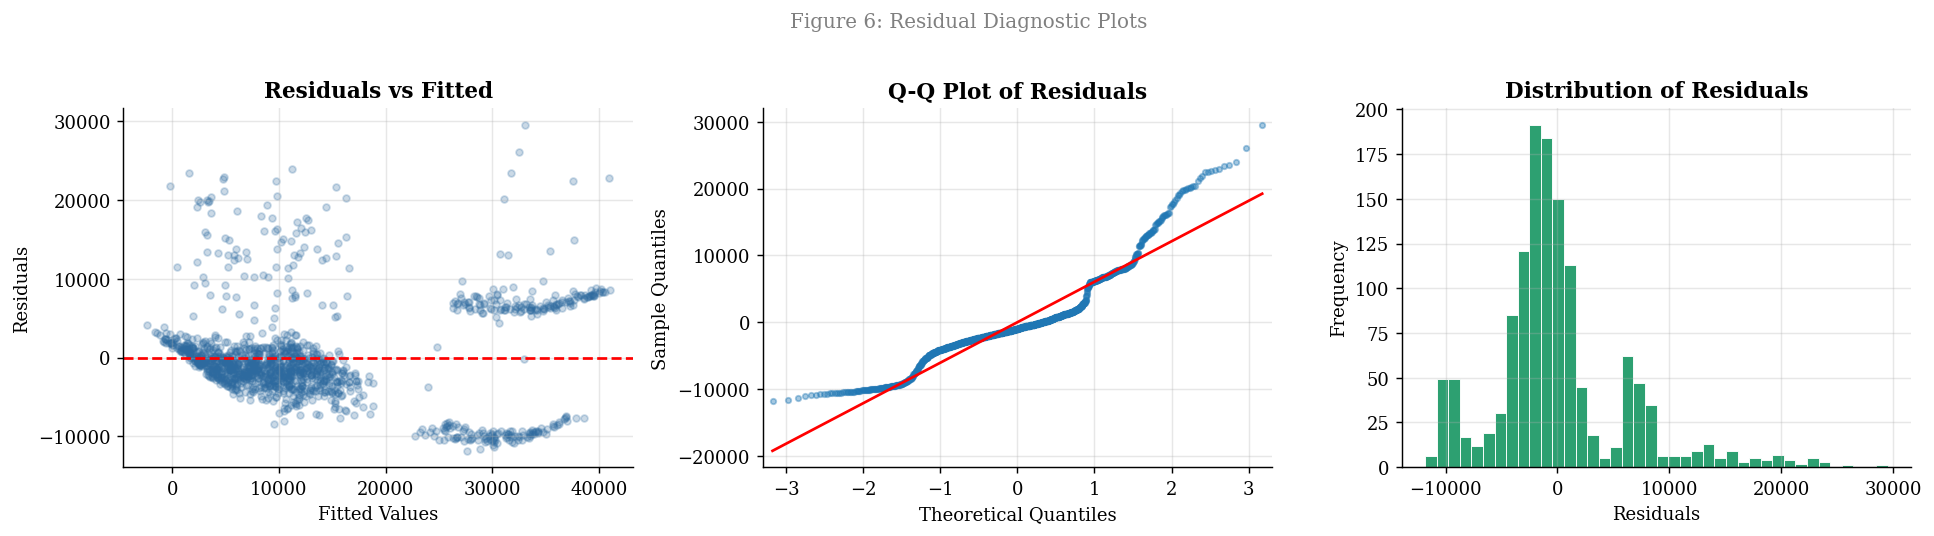

In [16]:
fitted    = model.fittedvalues
residuals = model.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals vs Fitted
axes[0].scatter(fitted, residuals, alpha=0.25, s=14, color=PALETTE[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted', fontweight='bold')

# Q-Q Plot
sm.qqplot(residuals, line='s', ax=axes[1], alpha=0.4, markersize=3)
axes[1].set_title('Q-Q Plot of Residuals', fontweight='bold')

# Histogram of residuals
axes[2].hist(residuals, bins=40, color=PALETTE[2], edgecolor='white', linewidth=0.5)
axes[2].set_xlabel('Residuals')
axes[2].set_ylabel('Frequency')
axes[2].set_title('Distribution of Residuals', fontweight='bold')

plt.suptitle('Figure 6: Residual Diagnostic Plots', y=1.02, fontsize=11, color='gray')
plt.tight_layout()
plt.savefig('fig6_residual_diagnostics.png', bbox_inches='tight')
plt.show()

### 7.2 Actual vs Predicted Values

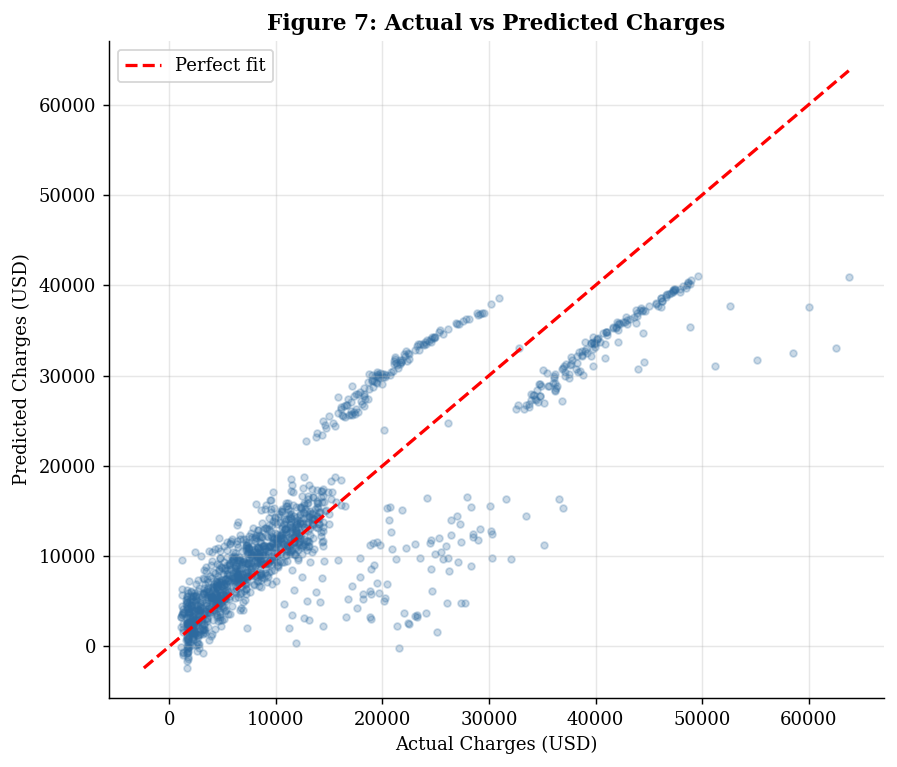

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y, fitted, alpha=0.25, s=14, color=PALETTE[0])
lims = [min(y.min(), fitted.min()), max(y.max(), fitted.max())]
ax.plot(lims, lims, 'r--', linewidth=1.8, label='Perfect fit')
ax.set_xlabel('Actual Charges (USD)')
ax.set_ylabel('Predicted Charges (USD)')
ax.set_title('Figure 7: Actual vs Predicted Charges', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig7_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

### 7.3 Multicollinearity Check (Variance Inflation Factor)

A Variance Inflation Factor (VIF) test is performed to detect multicollinearity among the independent variables. VIF values below **5** indicate acceptable levels of multicollinearity; values above **10** suggest a serious problem that may inflate coefficient estimates and reduce model reliability.


In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['Feature'] = PREDICTORS
vif_data['VIF'] = [
    variance_inflation_factor(X_const.values, i + 1)
    for i in range(len(PREDICTORS))
]
vif_data['Feature Label'] = ['Age', 'BMI', 'Children', 'Smoker (enc)', 'Sex (enc)']
vif_data['Interpretation'] = vif_data['VIF'].apply(
    lambda v: 'No multicollinearity' if v < 5 else ('Moderate' if v < 10 else 'High — concern')
)

print('VARIANCE INFLATION FACTOR (VIF) — Multicollinearity Diagnostics')
print('─' * 65)
print(vif_data[['Feature Label', 'VIF', 'Interpretation']].to_string(index=False))
print()
print('Threshold: VIF < 5 = acceptable | VIF 5–10 = moderate | VIF > 10 = problematic')


VARIANCE INFLATION FACTOR (VIF) — Multicollinearity Diagnostics
─────────────────────────────────────────────────────────────────
Feature Label      VIF       Interpretation
          Age 1.015129 No multicollinearity
          BMI 1.014578 No multicollinearity
     Children 1.002242 No multicollinearity
 Smoker (enc) 1.006457 No multicollinearity
    Sex (enc) 1.008878 No multicollinearity

Threshold: VIF < 5 = acceptable | VIF 5–10 = moderate | VIF > 10 = problematic


## 8. Sample Prediction

In [19]:
# Example: predict charges for a new individual
# Change these values to test different scenarios
sample = pd.DataFrame([{
    'const'      : 1,
    'age'        : 35,
    'bmi'        : 28.5,
    'children'   : 2,
    'smoker_enc' : 0,   # 0 = non-smoker, 1 = smoker
    'sex_enc'    : 1    # 1 = male, 0 = female
}])

prediction = model.predict(sample)[0]
print(f'Sample Input:')
print(f'  Age: 35, BMI: 28.5, Children: 2, Smoker: No, Sex: Male')
print(f'\nPredicted Medical Charges: USD {prediction:,.2f}')

Sample Input:
  Age: 35, BMI: 28.5, Children: 2, Smoker: No, Sex: Male

Predicted Medical Charges: USD 6,975.83
